# Product Category Classification

Cilj ovog projekta je razvoj modela za automatsku klasifikaciju proizvoda na osnovu naziva proizvoda.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [2]:
df = pd.read_csv("products.csv")

df.head()

,product ID,Product Title,Merchant ID,Category Label,_Product Code,Number_of_Views,Merchant Rating,Listing Date
0,1,apple iphone 8 plus 64gb silver,1,Mobile Phones,QA-2276-XC,860.0,2.5,5/10/2024
1,2,apple iphone 8 plus 64 gb spacegrau,2,Mobile Phones,KA-2501-QO,3772.0,4.8,12/31/2024
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,Mobile Phones,FP-8086-IE,3092.0,3.9,11/10/2024
3,4,apple iphone 8 plus 64gb space grey,4,Mobile Phones,YI-0086-US,466.0,3.4,5/2/2022
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,Mobile Phones,NZ-3586-WP,4426.0,1.6,4/12/2023


In [4]:
print("Dimenzije dataseta:")
print(df.shape)

print("\nNazivi kolona:")
print(df.columns)

print("\nNedostajuće vrijednosti:")
print(df.isnull().sum())

print("\nBroj kategorija:")
print(df[" Category Label"].nunique())

Dimenzije dataseta:
(35311, 8)

Nazivi kolona:
Index(['product ID', 'Product Title', 'Merchant ID', ' Category Label',
       '_Product Code', 'Number_of_Views', 'Merchant Rating',
       ' Listing Date  '],
      dtype='str')

Nedostajuće vrijednosti:
product ID           0
Product Title      172
Merchant ID          0
 Category Label     44
_Product Code       95
Number_of_Views     14
Merchant Rating    170
 Listing Date       59
dtype: int64

Broj kategorija:
13


In [6]:
df.dropna(
    subset=["Product Title", " Category Label"],
    inplace=True
)

df["Product Title"] = (
    df["Product Title"]
    .astype(str)
    .str.lower()
)

df[" Category Label"] = (
    df[" Category Label"]
    .astype(str)
    .str.strip()
)

In [7]:
df["title_length"] = (
    df["Product Title"]
    .apply(len)
)

df["word_count"] = (
    df["Product Title"]
    .apply(lambda x: len(x.split()))
)

df[
    [
        "Product Title",
        "title_length",
        "word_count"
    ]
].head()

,Product Title,title_length,word_count
0,apple iphone 8 plus 64gb silver,31,6
1,apple iphone 8 plus 64 gb spacegrau,35,7
2,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,70,13
3,apple iphone 8 plus 64gb space grey,35,7
4,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,54,11


Kreirane su dodatne karakteristike koje opisuju dužinu naziva proizvoda i broj riječi. Ove informacije mogu pomoći u boljem razumijevanju strukture podataka.

In [8]:
X = df["Product Title"]

y = df[" Category Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [9]:
vectorizer = TfidfVectorizer()

X_train_vec = vectorizer.fit_transform(X_train)

X_test_vec = vectorizer.transform(X_test)

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "MultinomialNB": MultinomialNB(),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "LinearSVC":
        LinearSVC()
}



Logistic Regression
Accuracy: 0.9541
                  precision    recall  f1-score   support

             CPU       0.00      0.00      0.00        17
            CPUs       0.98      1.00      0.99       749
 Digital Cameras       0.99      0.99      0.99       538
     Dishwashers       0.93      0.96      0.95       681
        Freezers       0.99      0.93      0.96       440
 Fridge Freezers       0.95      0.94      0.94      1094
         Fridges       0.86      0.92      0.89       687
      Microwaves       0.99      0.96      0.97       466
    Mobile Phone       0.00      0.00      0.00        11
   Mobile Phones       0.96      0.99      0.97       801
             TVs       0.97      0.99      0.98       708
Washing Machines       0.95      0.95      0.95       803
          fridge       0.00      0.00      0.00        25

        accuracy                           0.95      7020
       macro avg       0.74      0.74      0.74      7020
    weighted avg       0.95    

C:\Users\roman\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\roman\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\roman\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

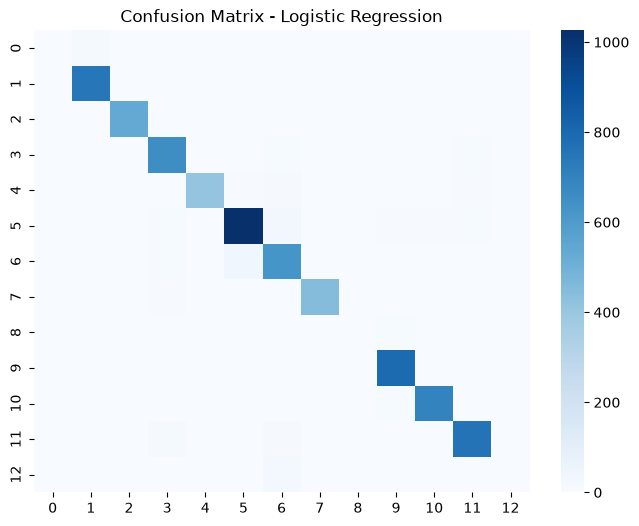



MultinomialNB
Accuracy: 0.9325


C:\Users\roman\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\roman\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\roman\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

                  precision    recall  f1-score   support

             CPU       0.00      0.00      0.00        17
            CPUs       0.98      1.00      0.99       749
 Digital Cameras       0.99      1.00      0.99       538
     Dishwashers       0.98      0.95      0.97       681
        Freezers       1.00      0.57      0.73       440
 Fridge Freezers       0.77      0.99      0.86      1094
         Fridges       0.89      0.83      0.86       687
      Microwaves       0.99      0.97      0.98       466
    Mobile Phone       0.00      0.00      0.00        11
   Mobile Phones       0.98      0.99      0.98       801
             TVs       0.99      0.99      0.99       708
Washing Machines       0.98      0.96      0.97       803
          fridge       0.00      0.00      0.00        25

        accuracy                           0.93      7020
       macro avg       0.73      0.71      0.72      7020
    weighted avg       0.93      0.93      0.93      7020



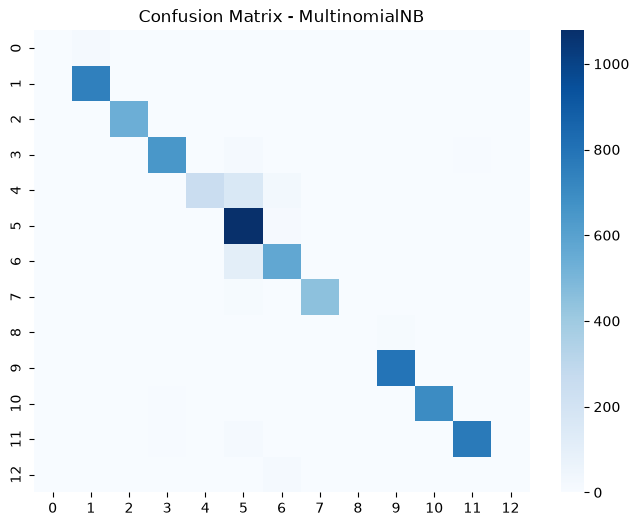



Decision Tree
Accuracy: 0.9262
                  precision    recall  f1-score   support

             CPU       0.00      0.00      0.00        17
            CPUs       0.98      0.98      0.98       749
 Digital Cameras       0.99      0.96      0.98       538
     Dishwashers       0.92      0.92      0.92       681
        Freezers       0.90      0.90      0.90       440
 Fridge Freezers       0.89      0.92      0.90      1094
         Fridges       0.86      0.83      0.84       687
      Microwaves       0.98      0.95      0.96       466
    Mobile Phone       0.00      0.00      0.00        11
   Mobile Phones       0.93      0.97      0.95       801
             TVs       0.97      0.98      0.97       708
Washing Machines       0.95      0.92      0.93       803
          fridge       0.00      0.00      0.00        25

        accuracy                           0.93      7020
       macro avg       0.72      0.72      0.72      7020
    weighted avg       0.93      0.93

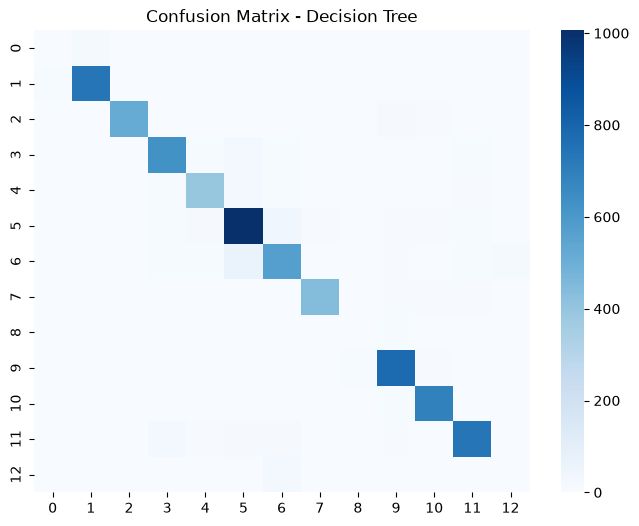



LinearSVC
Accuracy: 0.9665
                  precision    recall  f1-score   support

             CPU       0.00      0.00      0.00        17
            CPUs       0.98      1.00      0.99       749
 Digital Cameras       0.99      1.00      1.00       538
     Dishwashers       0.95      0.97      0.96       681
        Freezers       0.99      0.97      0.98       440
 Fridge Freezers       0.97      0.96      0.96      1094
         Fridges       0.90      0.93      0.92       687
      Microwaves       0.99      0.98      0.98       466
    Mobile Phone       0.00      0.00      0.00        11
   Mobile Phones       0.98      1.00      0.99       801
             TVs       0.98      1.00      0.99       708
Washing Machines       0.96      0.96      0.96       803
          fridge       0.00      0.00      0.00        25

        accuracy                           0.97      7020
       macro avg       0.75      0.75      0.75      7020
    weighted avg       0.96      0.97    

C:\Users\roman\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\roman\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\roman\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

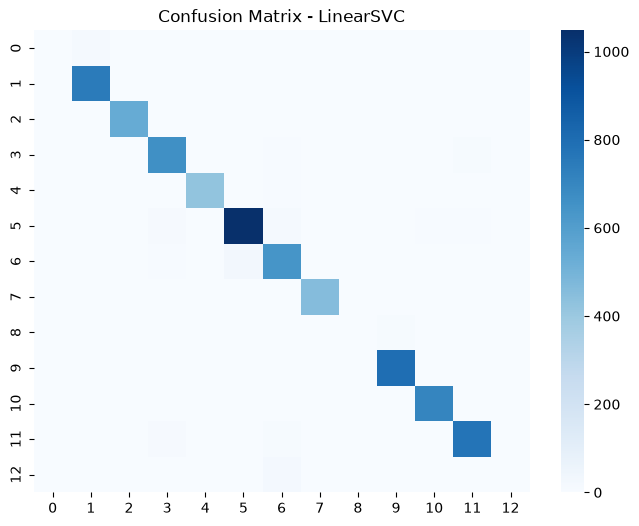

In [11]:
results = []

for name, model in models.items():

    print("\n")
    print("=" * 50)
    print(name)
    print("=" * 50)

    model.fit(
        X_train_vec,
        y_train
    )

    predictions = model.predict(
        X_test_vec
    )

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    results.append(
        [name, accuracy]
    )

    print(
        "Accuracy:",
        round(
            accuracy,
            4
        )
    )

    print(
        classification_report(
            y_test,
            predictions
        )
    )

    cm = confusion_matrix(
        y_test,
        predictions
    )

    plt.figure(
        figsize=(8,6)
    )

    sns.heatmap(
        cm,
        cmap="Blues"
    )

    plt.title(
        f"Confusion Matrix - {name}"
    )

    plt.show()

In [12]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy"
    ]
)

results_df.sort_values(
    by="Accuracy",
    ascending=False
)

,Model,Accuracy
3,LinearSVC,0.966524
0,Logistic Regression,0.954131
1,MultinomialNB,0.932479
2,Decision Tree,0.926211


In [13]:
best_model_name = (
    results_df
    .sort_values(
        by="Accuracy",
        ascending=False
    )
    .iloc[0]["Model"]
)

print(
    "Najbolji model:",
    best_model_name
)

Najbolji model: LinearSVC


In [14]:
final_model = LinearSVC()

final_model.fit(
    X_train_vec,
    y_train
)

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

In [15]:
with open(
    "model.pkl",
    "wb"
) as f:

    pickle.dump(
        final_model,
        f
    )

with open(
    "vectorizer.pkl",
    "wb"
) as f:

    pickle.dump(
        vectorizer,
        f
    )

print(
    "Model sačuvan."
)

Model sačuvan.


In [16]:
import pandas as pd
import pickle

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

df = pd.read_csv(
    "products.csv"
)

df.dropna(
    subset=[
        "Product Title",
        " Category Label"
    ],
    inplace=True
)

X = df["Product Title"]
y = df[" Category Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

vectorizer = TfidfVectorizer()

X_train_vec = vectorizer.fit_transform(
    X_train
)

model = LinearSVC()

model.fit(
    X_train_vec,
    y_train
)

with open(
    "model.pkl",
    "wb"
) as f:

    pickle.dump(
        model,
        f
    )

with open(
    "vectorizer.pkl",
    "wb"
) as f:

    pickle.dump(
        vectorizer,
        f
    )

print(
    "Model sačuvan."
)

Model sačuvan.


In [17]:
import pickle

with open(
    "model.pkl",
    "rb"
) as f:

    model = pickle.load(f)

with open(
    "vectorizer.pkl",
    "rb"
) as f:

    vectorizer = pickle.load(f)

print(
    "Product Category Predictor"
)

while True:

    product = input(
        "\nUnesi naziv proizvoda (ili exit): "
    )

    if product.lower() == "exit":
        break

    vector = vectorizer.transform(
        [product]
    )

    prediction = model.predict(
        vector
    )

    print(
        "\nPredložena kategorija:"
    )

    print(
        prediction[0]
    )

Product Category Predictor



Unesi naziv proizvoda (ili exit):  iphone 7 32gb gold



Predložena kategorija:
Mobile Phones



Unesi naziv proizvoda (ili exit):  exit


# Zaključak 

U ovom projektu razvijen je model za automatsku klasifikaciju proizvoda na osnovu naziva proizvoda.

Prvo su učitani i analizirani podaci iz skupa products.csv. Nakon toga uklonjene su nedostajuće vrijednosti i pripremljeni podaci za treniranje modela. Za obradu tekstualnih podataka korišten je TF-IDF vektorizator koji pretvara nazive proizvoda u numerički oblik pogodan za mašinsko učenje.

Testirana su četiri različita modela: Logistic Regression, Multinomial Naive Bayes, Decision Tree i LinearSVC. Nakon poređenja rezultata, najbolji model pokazao se LinearSVC, zbog najboljih ukupnih performansi na testnom skupu podataka.
Tokom rada isprobane su i dodatne karakteristike kao što su dužina naziva proizvoda i broj riječi u nazivu. Međutim, pokazalo se da najveći doprinos kvalitetu predikcije daje sam tekst naziva proizvoda.

Na osnovu dobijenih rezultata, LinearSVC je izabran kao finalni model, sačuvan u .pkl formatu i korišten za interaktivnu predikciju kategorije novih proizvoda.
Ovaj projekat pokazuje kako se tehnike mašinskog učenja mogu koristiti za automatizaciju procesa kategorizacije proizvoda i smanjenje potrebe za ručnim unosom podataka.